/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


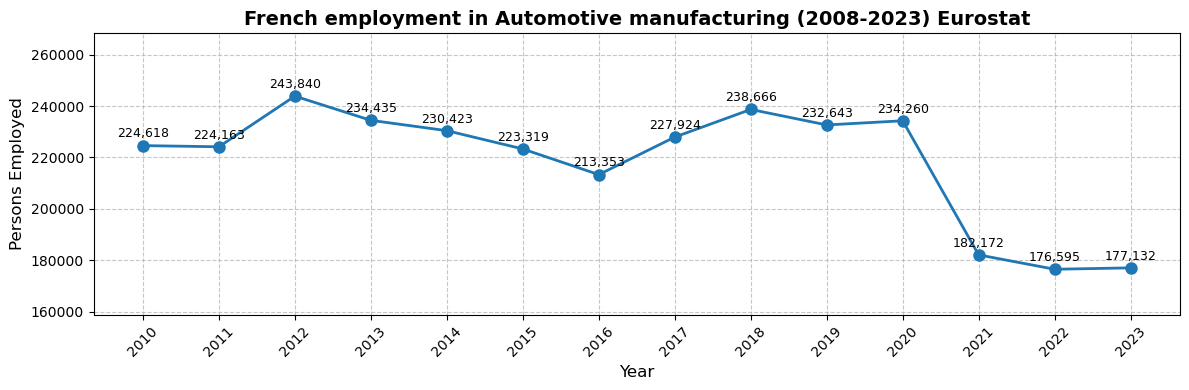

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_old = pd.read_excel("../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx", sheet_name=3, skiprows=8)
df_old.rename(columns={'TIME': 'GEO_Codes', 'TIME.1': 'GEO_Labels'}, inplace=True)
df_old = df_old[df_old['GEO_Codes'].notna() & (df_old['GEO_Codes'] != 'GEO (Codes)')].copy()

fr_old = df_old[df_old['GEO_Codes'] == 'FR'].copy()
years_old = [str(y) for y in range(2008, 2021)]
fr_old_data = pd.to_numeric(fr_old[years_old].iloc[0].astype(str).str.replace(':', 'NaN').str.replace(',', '').str.strip(), errors='coerce')

df_new = pd.read_csv("/Users/majdshamashan/Downloads/estimated_total_persons_employed_2021_2023.csv")
fr_new = df_new[df_new['GEO_Codes'] == 'FR'].copy()
years_new = ['2021', '2022', '2023']
fr_new_data = pd.to_numeric(fr_new[years_new].iloc[0], errors='coerce')

fr_full_data = pd.concat([fr_old_data, fr_new_data])

plt.figure(figsize=(12, 4))
plt.plot(fr_full_data.index, fr_full_data.values, marker='o', linestyle='-', color='tab:blue', linewidth=2, markersize=8)
plt.title('French employment in Automotive manufacturing (2008-2023) Eurostat', fontweight='bold', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Persons Employed', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

for i, v in enumerate(fr_full_data.values):
    if not np.isnan(v):
        plt.text(i, v + 2000, f'{int(v):,}', ha='center', va='bottom', fontsize=9)

plt.ylim(fr_full_data.min() * 0.9, fr_full_data.max() * 1.1)
plt.tight_layout()
plt.savefig("france_automotive_employment_2008_2023.png")
plt.show()

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


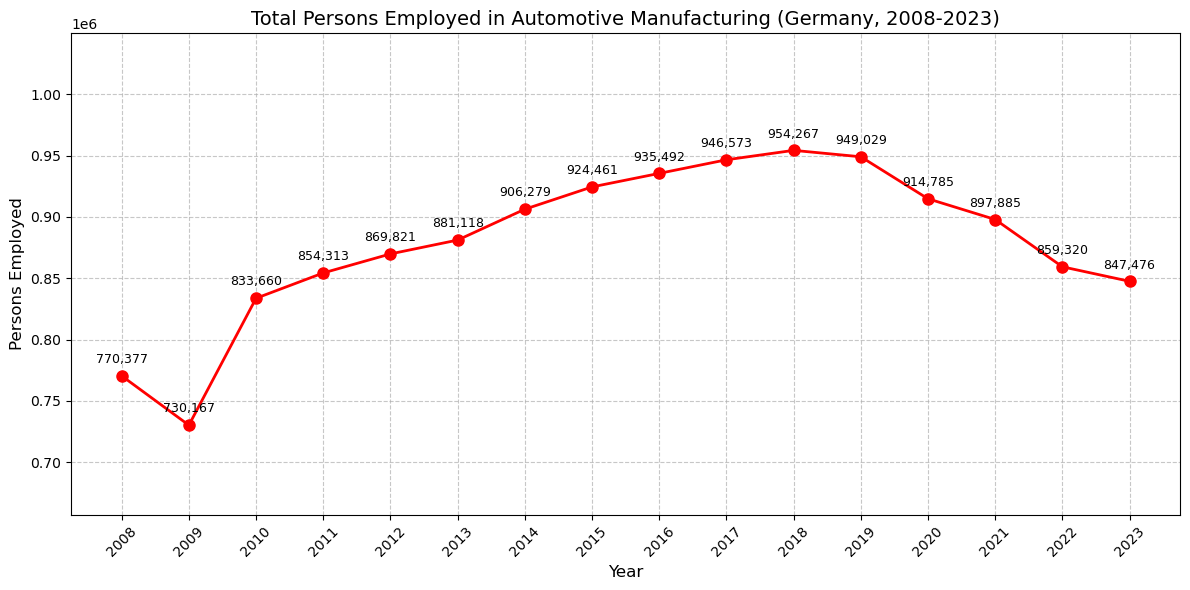

In [ ]:

df_old = pd.read_excel("../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx", sheet_name=3, skiprows=8)
df_old.rename(columns={'TIME': 'GEO_Codes', 'TIME.1': 'GEO_Labels'}, inplace=True)
df_old = df_old[df_old['GEO_Codes'].notna() & (df_old['GEO_Codes'] != 'GEO (Codes)')].copy()

de_old = df_old[df_old['GEO_Codes'] == 'DE'].copy()
years_old = [str(y) for y in range(2008, 2021)]
de_old_data = pd.to_numeric(de_old[years_old].iloc[0].astype(str).str.replace(':', 'NaN').str.replace(',', '').str.strip(), errors='coerce')

df_new = pd.read_csv("/Users/majdshamashan/Downloads/estimated_total_persons_employed_2021_2023.csv")
de_new = df_new[df_new['GEO_Codes'] == 'DE'].copy()
years_new = ['2021', '2022', '2023']
de_new_data = pd.to_numeric(de_new[years_new].iloc[0], errors='coerce')

de_full_data = pd.concat([de_old_data, de_new_data])

plt.figure(figsize=(12, 6))
plt.plot(de_full_data.index, de_full_data.values, marker='o', linestyle='-', color='r', linewidth=2, markersize=8)
plt.title('Total Persons Employed in Automotive Manufacturing (Germany, 2008-2023)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Persons Employed', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# Add data labels
for i, v in enumerate(de_full_data.values):
    if not np.isnan(v):
        plt.text(i, v + 8000, f'{int(v):,}', ha='center', va='bottom', fontsize=9)

plt.ylim(de_full_data.min() * 0.9, de_full_data.max() * 1.1)
plt.tight_layout()
plt.savefig("germany_automotive_employment_2008_2023.png")
plt.show()

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


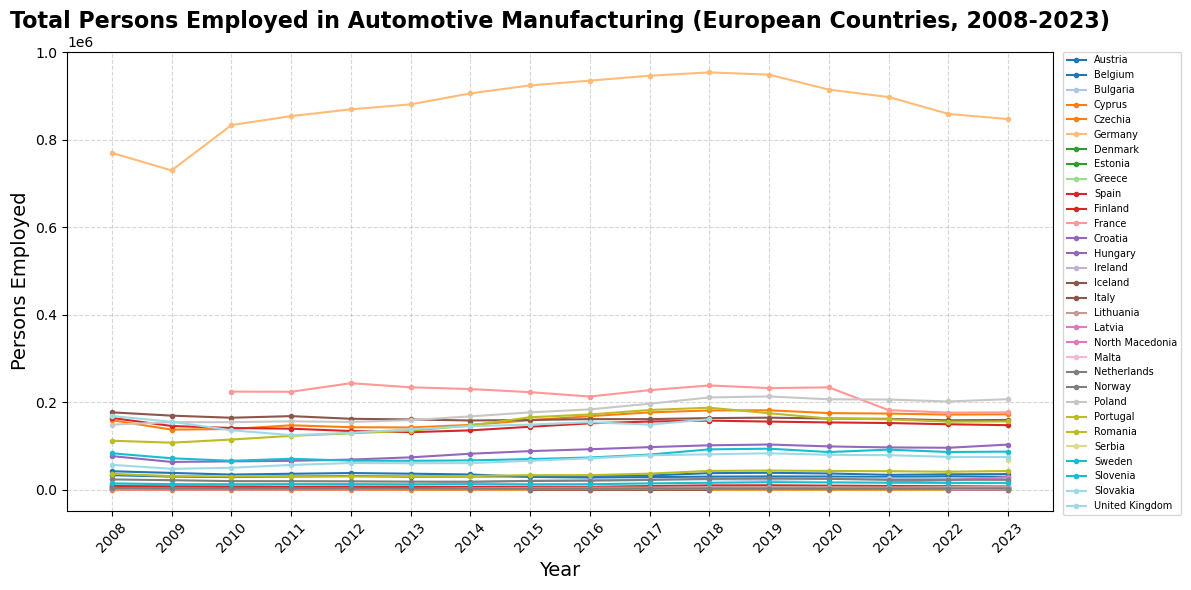

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the 2008-2020 dataset
df_old = pd.read_excel("../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx", sheet_name=3, skiprows=8)
df_old.rename(columns={'TIME': 'GEO_Codes', 'TIME.1': 'GEO_Labels'}, inplace=True)
df_old = df_old[df_old['GEO_Codes'].notna() & (df_old['GEO_Codes'] != 'GEO (Codes)')].copy()

# Keep only country-level data (NUTS 0 usually has 2-letter codes)
df_old_countries = df_old[df_old['GEO_Codes'].str.len() == 2].copy()
years_old = [str(y) for y in range(2008, 2021)]
df_old_countries = df_old_countries[['GEO_Codes', 'GEO_Labels'] + years_old]

# 2. Load the 2021-2023 estimated dataset
df_new = pd.read_csv("/Users/majdshamashan/Downloads/estimated_total_persons_employed_2021_2023.csv")
df_new_countries = df_new[df_new['GEO_Codes'].str.len() == 2].copy()

# 3. Merge the datasets
df_merged = pd.merge(df_old_countries, df_new_countries, on=['GEO_Codes', 'GEO_Labels'], how='outer')

# 4. Clean the data (remove Eurostat flags like 'b', 'C', ':', spaces, commas)
years_all = [str(y) for y in range(2008, 2024)]
for year in years_all:
    if year in df_merged.columns:
        # Keep only digits and decimal points
        df_merged[year] = pd.to_numeric(
            df_merged[year].astype(str).replace(r'[^0-9.]', '', regex=True), 
            errors='coerce'
        )

# Set index to GEO_Labels for easier plotting
df_merged.set_index('GEO_Labels', inplace=True)
df_plot = df_merged[years_all].dropna(how='all').copy()

# 5. Plotting
plt.figure(figsize=(12, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(df_plot)))

for i, (country, row) in enumerate(df_plot.iterrows()):
    plt.plot(row.index, row.values, marker='.', linewidth=1.5, label=country, color=colors[i])

plt.title('Total Persons Employed in Automotive Manufacturing (European Countries, 2008-2023)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=14)
plt.ylabel('Persons Employed', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)

# Put legend outside the plot
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', ncol=1, fontsize=7, borderaxespad=0.)

plt.tight_layout()
plt.savefig("all_countries_automotive_employment_2008_2023.png", dpi=150)
plt.show()

/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_53783/3002303934.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(['{:,.0f}'.format(x) for x in current_values])


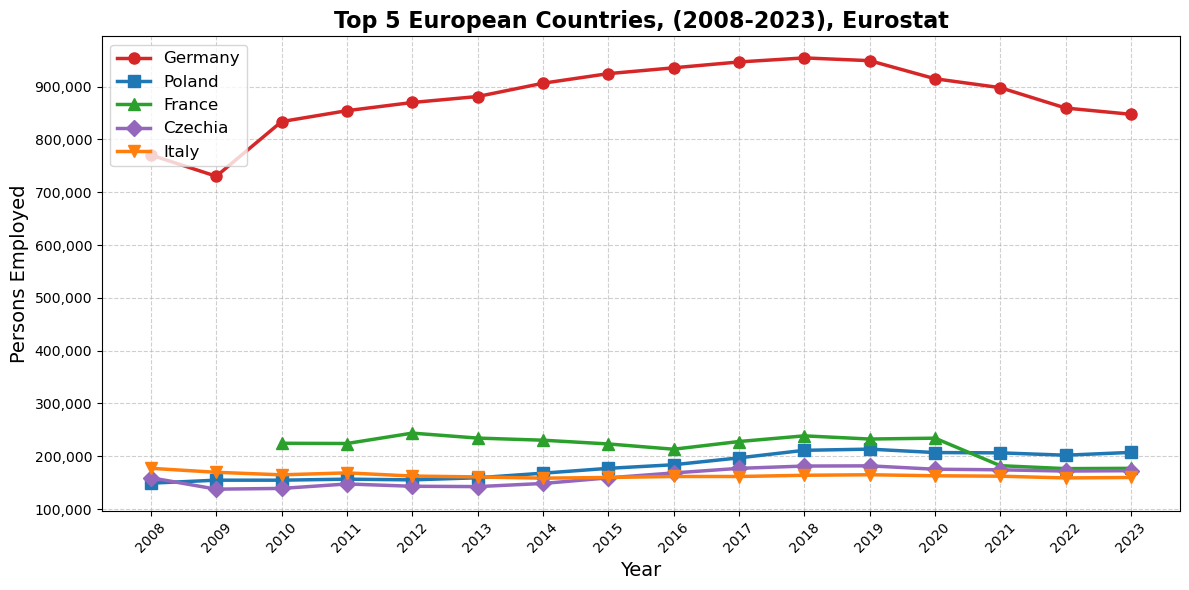

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the 2008-2020 dataset
# df_old = pd.read_csv("sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx - Sheet 3.csv", skiprows=8)
df_old.rename(columns={'TIME': 'GEO_Codes', 'TIME.1': 'GEO_Labels'}, inplace=True)
df_old = df_old[df_old['GEO_Codes'].notna() & (df_old['GEO_Codes'] != 'GEO (Codes)')].copy()

# Keep only country-level data (NUTS 0 usually has 2-letter codes)
df_old_countries = df_old[df_old['GEO_Codes'].str.len() == 2].copy()
years_old = [str(y) for y in range(2008, 2021)]
df_old_countries = df_old_countries[['GEO_Codes', 'GEO_Labels'] + years_old]

# 2. Load the 2021-2023 estimated dataset
# df_new = pd.read_csv("estimated_total_persons_employed_2021_2023.csv")
df_new_countries = df_new[df_new['GEO_Codes'].str.len() == 2].copy()

# 3. Merge datasets
df_merged = pd.merge(df_old_countries, df_new_countries, on=['GEO_Codes', 'GEO_Labels'], how='outer')

# 4. Clean the data
years_all = [str(y) for y in range(2008, 2024)]
for year in years_all:
    if year in df_merged.columns:
        df_merged[year] = pd.to_numeric(
            df_merged[year].astype(str).replace(r'[^0-9.]', '', regex=True), 
            errors='coerce'
        )

df_merged.set_index('GEO_Labels', inplace=True)
df_plot = df_merged[years_all].dropna(how='all').copy()

# 5. Get Top 5 countries in 2023
top5_countries = df_plot['2023'].sort_values(ascending=False).head(5).index.tolist()
df_top5 = df_plot.loc[top5_countries]

# 6. Plotting
plt.figure(figsize=(12, 6))
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e']
markers = ['o', 's', '^', 'D', 'v']

for i, (country, row) in enumerate(df_top5.iterrows()):
    plt.plot(row.index, row.values, marker=markers[i], linewidth=2.5, markersize=8, label=country, color=colors[i])

plt.title('Top 5 European Countries, (2008-2023), Eurostat', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=14)
plt.ylabel('Persons Employed', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)

# Format y-axis with commas
current_values = plt.gca().get_yticks()
plt.gca().set_yticklabels(['{:,.0f}'.format(x) for x in current_values])

plt.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.savefig("top5_countries_automotive_employment_2008_2023.png", dpi=150)

In [ ]:

country_mapping = {
    'DE': 'Germany',
    'PL': 'Poland',
    'FR': 'France',
    'CZ': 'Czechia',
    'IT': 'Italy'
}

mask = df['GEO_Codes'].apply(lambda x: isinstance(x, str) and 
                                       x[:2] in country_mapping and 
                                       len(x) == 4 and 
                                       not x.endswith('Z'))

regions_df = df[mask].copy()

# Add the 'Country' column
regions_df['Country'] = regions_df['GEO_Codes'].str[:2].map(country_mapping)

# Drop missing 2023 values
regions_df = regions_df.dropna(subset=['2023'])

# Group by Country, and slice the Top 4 regions for each one based on 2023 employment
top_regions = (
    regions_df.sort_values(['Country', '2023'], ascending=[True, False])
    .groupby('Country')
    .head(5) 
)

# Custom sort to keep the 'Top 5' countries grouped in order of their national size
country_order = ['Germany', 'Poland', 'France', 'Czechia', 'Italy']
top_regions['Country'] = pd.Categorical(top_regions['Country'], categories=country_order, ordered=True)

# Finalize the table format
final_table = top_regions.sort_values(['Country', '2023'], ascending=[True, False])
final_table = final_table[['Country', 'GEO_Codes', 'GEO_Labels', '2023']]

final_table



,Country,GEO_Codes,GEO_Labels,2023
49,Germany,DE11,Stuttgart,151905.0
54,Germany,DE21,Oberbayern,104400.0
76,Germany,DE91,Braunschweig,82764.0
50,Germany,DE12,Karlsruhe,41554.0
55,Germany,DE22,Niederbayern,37260.0
302,Poland,PL22,Śląskie,58644.0
308,Poland,PL51,Dolnośląskie,37467.0
304,Poland,PL41,Wielkopolskie,27370.0
319,Poland,PL82,Podkarpackie,13965.0
301,Poland,PL21,Małopolskie,13650.0


/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_53783/507472312.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:,.0f}'.format(x) for x in current_values])
/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_53783/507472312.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:,.0f}'.format(x) for x in current_values])
/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_53783/507472312.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:,.0f}'.format(x) for x in current_values])
/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_53783/507472312.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e.

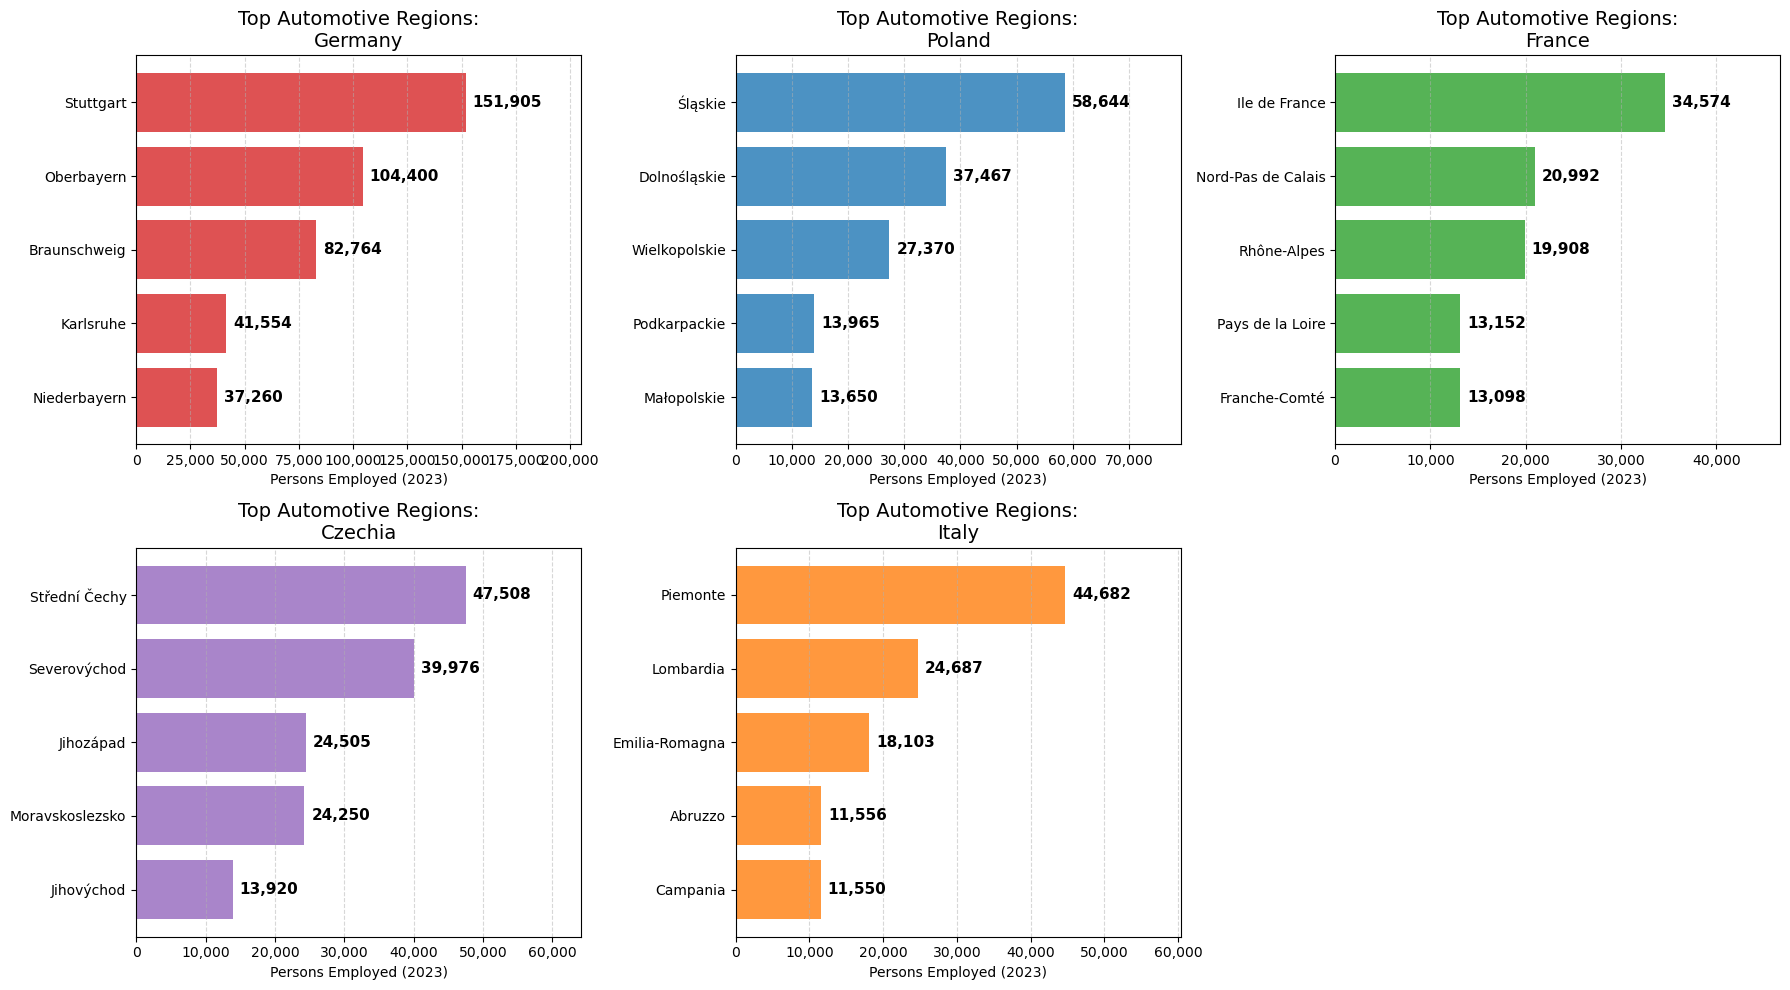

In [34]:


# 2. Get the unique countries to plot
countries = final_table['Country'].unique()

# 3. Create a figure with subplots (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() 

# 4. Define specific colors to match our previous country timelines
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e']

# 5. Loop through the countries and plot each one
for i, country in enumerate(countries):
    ax = axes[i]
    
    # Filter data for the specific country and sort ascending (so largest is at the top)
    country_data = final_table[final_table['Country'] == country].sort_values(by='2023', ascending=True)
    
    # Create horizontal bar chart
    bars = ax.barh(country_data['GEO_Labels'], country_data['2023'], color=colors[i], alpha=0.8)
    
    # Titles and labels
    ax.set_title(f'Top Automotive Regions:\n{country}', fontsize=14, )
    ax.set_xlabel('Persons Employed (2023)', fontsize=10)
    
    # Add data labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        ax.annotate(f'{int(width):,}',
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0),  # 5 points horizontal offset
                    textcoords="offset points",
                    ha='left', va='center', fontsize=11, fontweight='bold')
    
    # Extend x-axis limit by 35% to make room for the data labels
    max_val = country_data['2023'].max()
    ax.set_xlim(0, max_val * 1.35)
    
    # Format x-axis with commas
    current_values = ax.get_xticks()
    ax.set_xticklabels(['{:,.0f}'.format(x) for x in current_values])
    
    # Styling
    ax.tick_params(axis='y', labelsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

# 6. Remove the 6th empty subplot (since we only have 5 countries)
fig.delaxes(axes[5])

plt.tight_layout()

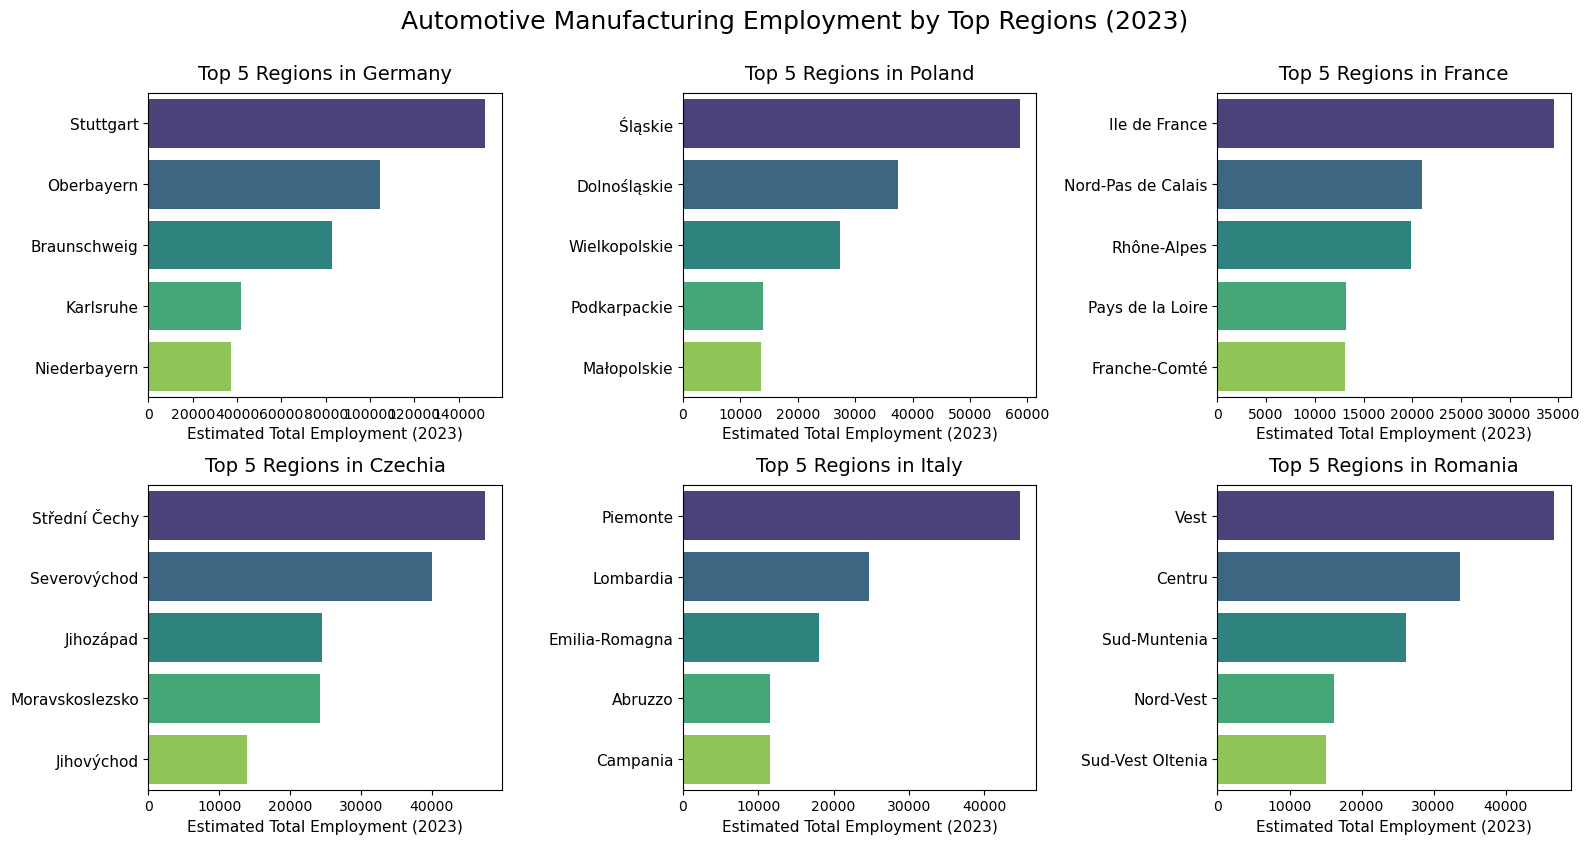

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# 1. Load the data
filename = "../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21203869_spreadsheet.xlsx"

# Read Sheet 1 (Employees per unit) and Sheet 2 (Local units)
df1 = pd.read_excel(filename, sheet_name='Sheet 1', header=8)
df2 = pd.read_excel(filename, sheet_name='Sheet 2', header=8)

# Clean and rename columns for 2023
df1 = df1.iloc[1:].rename(columns={'TIME': 'GEO_CODE', 'TIME.1': 'GEO_LABEL', '2023': 'Emp_per_unit'})
df1 = df1[['GEO_CODE', 'GEO_LABEL', 'Emp_per_unit']]

df2 = df2.iloc[1:].rename(columns={'TIME': 'GEO_CODE', 'TIME.1': 'GEO_LABEL', '2023': 'Units'})
df2 = df2[['GEO_CODE', 'GEO_LABEL', 'Units']]

# 2. Merge and Calculate
df = pd.merge(df1, df2, on=['GEO_CODE', 'GEO_LABEL'], how='inner')

# Convert string values to numeric, coercing errors (like the ':' confidentiality flags) to NaN
df['Emp_per_unit'] = pd.to_numeric(df['Emp_per_unit'].astype(str).str.replace(':', ''), errors='coerce')
df['Units'] = pd.to_numeric(df['Units'].astype(str).str.replace(':', ''), errors='coerce')

# Calculate total employment
df['Total_Employment'] = df['Emp_per_unit'] * df['Units']

# Drop missing values
df = df.dropna(subset=['Total_Employment'])

# 3. Process Regions and Countries
# NUTS 2 regions typically have 4-character codes (e.g., 'DE11', 'FR10')
regions = df[df['GEO_CODE'].str.len() == 4].copy()

# Extract the NUTS 0 country code (first 2 characters of the NUTS 2 code)
regions['Country_Code'] = regions['GEO_CODE'].str[:2]

# Determine the Top 6 employing countries by summing up their NUTS 2 regions
country_totals = regions.groupby('Country_Code')['Total_Employment'].sum().sort_values(ascending=False)
top_6_countries = country_totals.head(6).index.tolist()

# Mapping country codes to names for prettier plot titles
country_mapping = df[df['GEO_CODE'].str.len() == 2].set_index('GEO_CODE')['GEO_LABEL'].to_dict()

# 4. Generate the Visualization
# Set up a 2x3 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
axes = axes.flatten()

# Iterate through the top 6 countries and plot
for i, country_code in enumerate(top_6_countries):
    # Filter data for the specific country
    country_data = regions[regions['Country_Code'] == country_code]
    
    # Get the top 5 regions for this country
    top_regions = country_data.sort_values(by='Total_Employment', ascending=False).head(5)
    
    # Get the full country name, defaulting to code if not found
    country_name = country_mapping.get(country_code, country_code)
    
    # Create a horizontal bar plot
    sns.barplot(
        data=top_regions, 
        x='Total_Employment', 
        y='GEO_LABEL', 
        ax=axes[i], 
        palette='viridis'
    )
    
    # Format the subplot
    axes[i].set_title(f"Top 5 Regions in {country_name}", fontsize=14, pad=10)
    axes[i].set_xlabel("Estimated Total Employment (2023)", fontsize=11)
    axes[i].set_ylabel("")
    axes[i].tick_params(axis='y', labelsize=11)

# Adjust layout to prevent text clipping
plt.tight_layout()
plt.suptitle("Automotive Manufacturing Employment by Top Regions (2023)", fontsize=18, y=1.05)
plt.show()

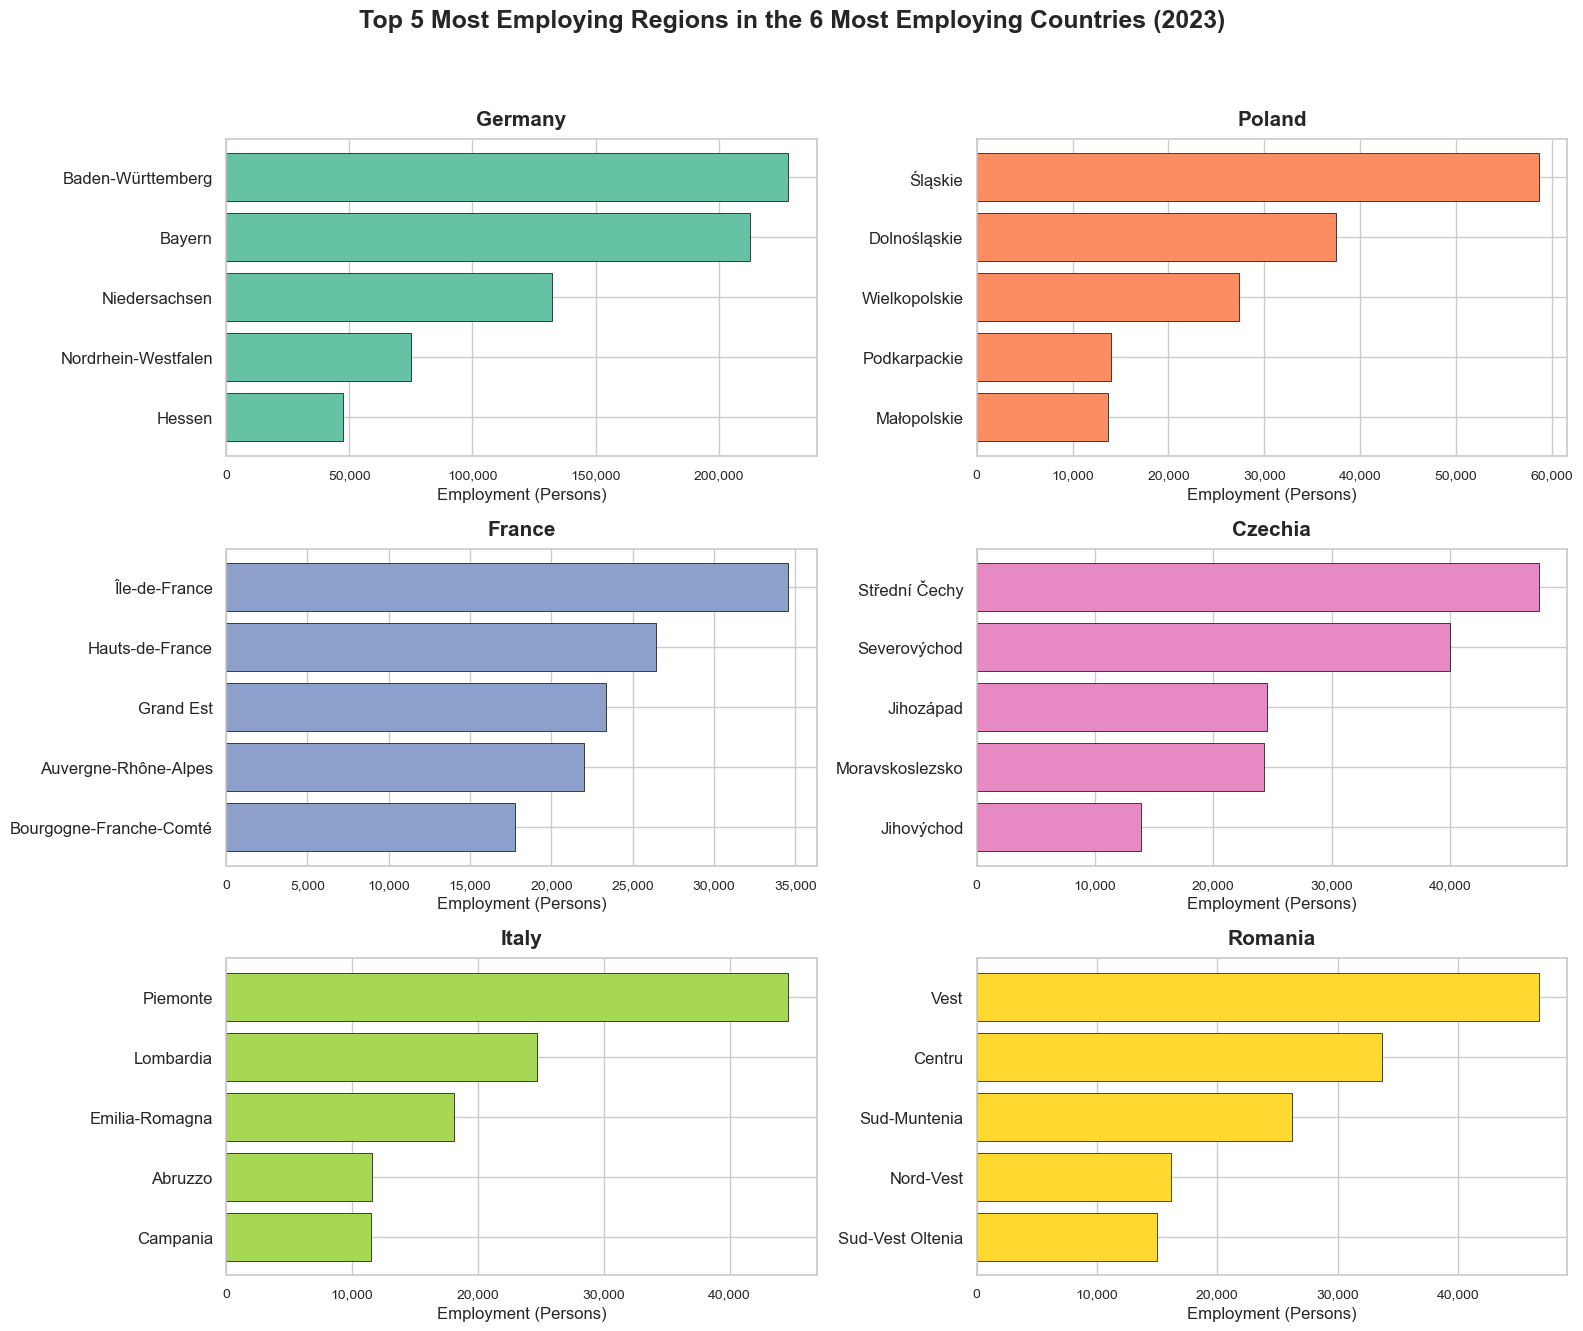

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
file_path = '/Users/majdshamashan/Downloads/merged_sbs_motor_vehicle_nuts_employment_derived.xlsx'
xls = pd.ExcelFile(file_path)
df = pd.read_excel(xls, sheet_name='Employment_Merged')

# 2. Clean the 2023 employment column
# The dataset uses ':' for missing values. We replace them with NaN and convert to numeric.
df['2023'] = pd.to_numeric(df['2023'].replace(':', np.nan), errors='coerce')

# 3. Calculate GEO code lengths to distinguish NUTS levels
# Country codes are length 2 (e.g., 'DE'). Regional codes are length > 2 (e.g., 'DE1', 'DE11').
df['len'] = df['GEO code'].astype(str).str.len()

# 4. Identify the top 6 countries by 2023 employment
countries = df[df['len'] == 2].copy()
top_6_countries = countries.sort_values(by='2023', ascending=False).head(6)

# Create a dictionary mapping the country code to its label (e.g., {'DE': 'Germany'})
country_mapping = dict(zip(top_6_countries['GEO code'], top_6_countries['GEO label']))

# 5. Extract top 5 regions for each of the top 6 countries
plot_data = []
for c_code, c_name in country_mapping.items():
    # Filter for sub-regions of this specific country
    subset = df[(df['GEO code'].astype(str).str.startswith(c_code)) & (df['len'] > 2)]
    
    # Select the appropriate sub-regional level
    # NUTS 2 usually has a length of 4. France has a mix in this dataset.
    if c_code == 'FR':
        regions = subset
    elif len(subset[subset['len'] == 4]) > 0:
        regions = subset[subset['len'] == 4]
    else:
        regions = subset[subset['len'] == 3]
        
    # Get the top 5 regions by employment
    top_5 = regions.sort_values(by='2023', ascending=False).head(5)
    
    for _, row in top_5.iterrows():
        plot_data.append({
            'Country': c_name,
            'Region': row['GEO label'],
            'Employment': row['2023']
        })

# Convert the extracted data into a clean DataFrame for plotting
df_plot = pd.DataFrame(plot_data)

# 6. Create the visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle('Top 5 Most Employing Regions in the 6 Most Employing Countries (2023)', 
             fontsize=18, y=0.98, fontweight='bold')

# Flatten the 3x2 axes array for easy iteration
axes = axes.flatten()

# Get a color palette with 6 distinct colors
colors = sns.color_palette("Set2", 6)

for i, c_name in enumerate(country_mapping.values()):
    ax = axes[i]
    c_data = df_plot[df_plot['Country'] == c_name]
    
    # Sort ascending so the highest bar is plotted at the top of the chart
    c_data = c_data.sort_values(by='Employment', ascending=True)
    
    # Create the horizontal bar plot
    ax.barh(c_data['Region'], c_data['Employment'], color=colors[i], edgecolor='black', linewidth=0.5)
    
    # Customize titles and labels
    ax.set_title(c_name, fontsize=15, pad=10, fontweight='bold')
    ax.set_xlabel('Employment (Persons)', fontsize=12)
    ax.set_ylabel('')
    
    # Format x-axis numbers with comma separators (e.g., 100,000)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
    
    # Adjust label sizes
    ax.tick_params(axis='y', labelsize=12)
    ax.tick_params(axis='x', labelsize=10)

# Adjust layout to prevent overlap and show the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Chart generated successfully and saved as 'top6_countries_top5_regions.png'


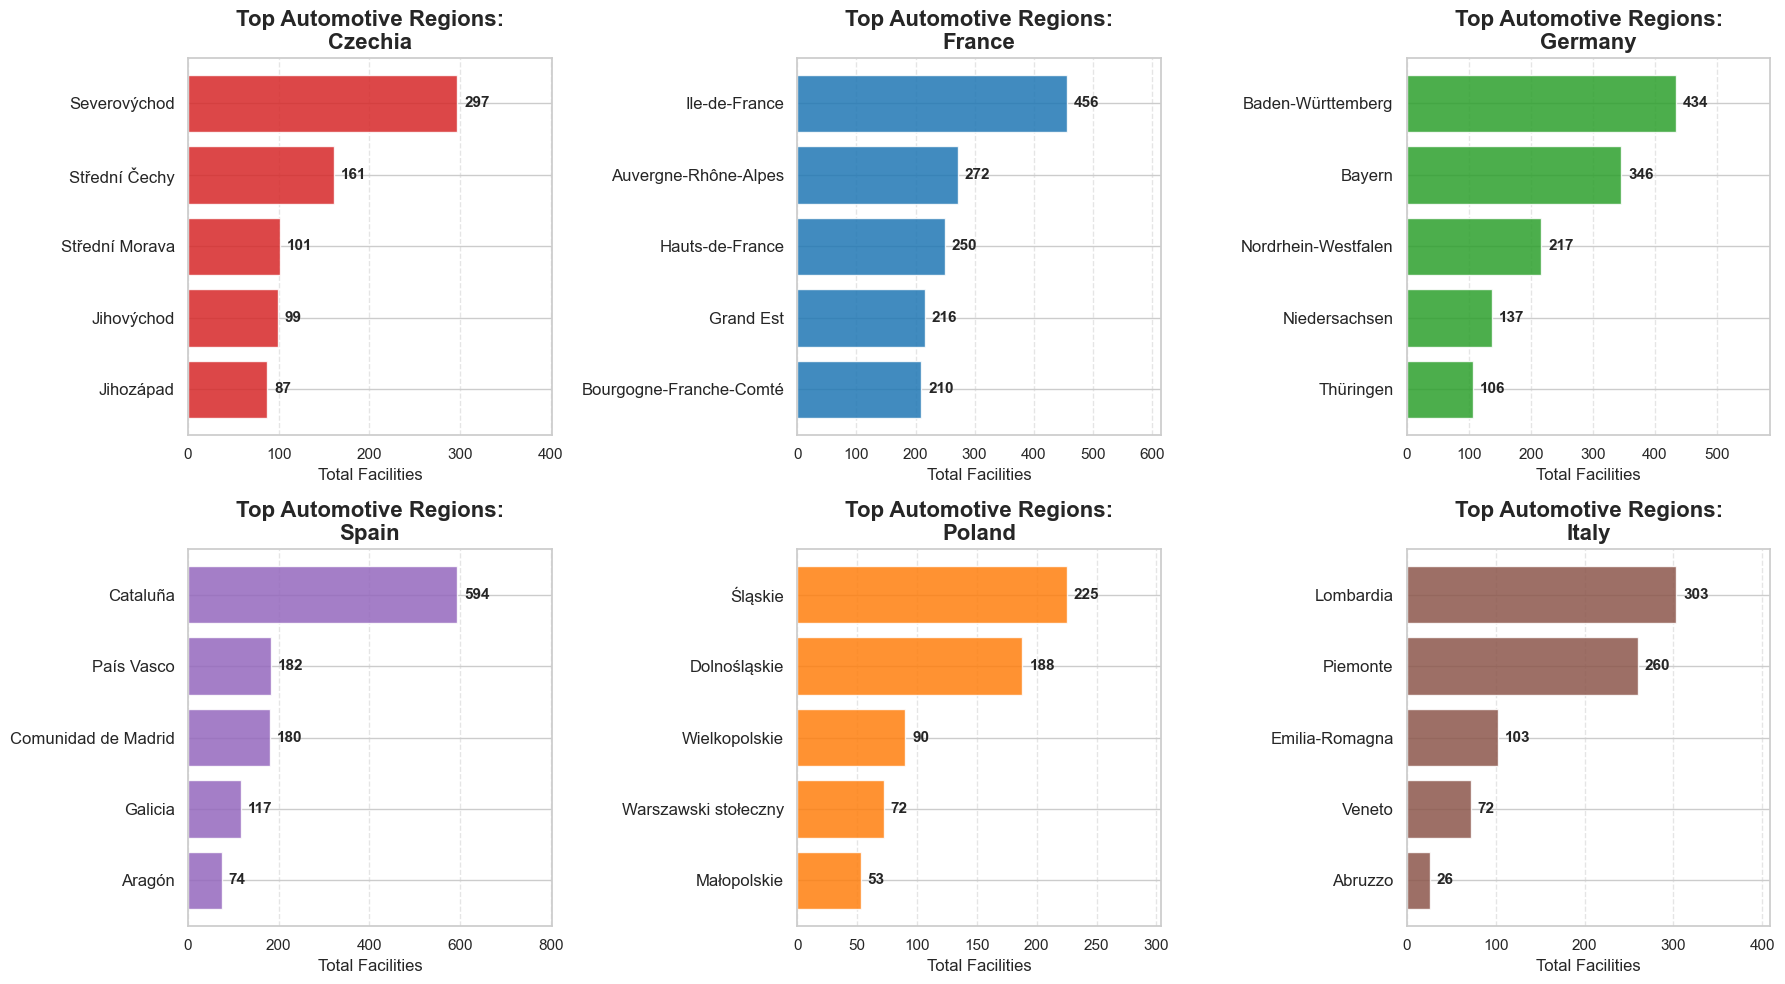

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
# Make sure "regional_counts.xlsx" is in the same directory as this script
df = pd.read_excel("../../03_data_raw/exploration_inputs/regional_counts.xlsx")

# 2. Define the Top 6 Countries to plot
countries = ['CZ', 'FR', 'DE', 'ES', 'PL', 'IT']
country_names = {
    'CZ': 'Czechia', 
    'FR': 'France', 
    'DE': 'Germany', 
    'ES': 'Spain', 
    'PL': 'Poland', 
    'IT': 'Italy'
}

# 3. Define valid macro-regions to prevent double-counting overlapping sub-regions
# This strictly filters France to its 13 regions and Germany to its 16 states
valid_regions = {
    'DE': [
        "Baden-Württemberg", "Bayern", "Berlin", "Brandenburg", "Bremen", 
        "Hamburg", "Hessen", "Mecklenburg-Vorpommern", "Niedersachsen", 
        "Nordrhein-Westfalen", "Rheinland-Pfalz", "Saarland", "Sachsen", 
        "Sachsen-Anhalt", "Schleswig-Holstein", "Thüringen"
    ],
    'FR': [
        "Ile-de-France", "Centre — Val de Loire", "Bourgogne-Franche-Comté",
        "Normandie", "Hauts-de-France", "Grand Est", "Pays de la Loire",
        "Bretagne", "Nouvelle-Aquitaine", "Occitanie", "Auvergne-Rhône-Alpes",
        "Provence-Alpes-Côte d’Azur", "Corse"
    ],
    'CZ': ["Praha", "Střední Čechy", "Jihozápad", "Severozápad", "Severovýchod", "Jihovýchod", "Střední Morava", "Moravskoslezsko"],
    'PL': ["Małopolskie", "Śląskie", "Wielkopolskie", "Zachodniopomorskie", "Lubuskie", "Dolnośląskie", "Opolskie", "Kujawsko-Pomorskie", "Pomorskie", "Warmińsko-Mazurskie", "Podlaskie", "Warszawski stołeczny", "Mazowieckie regionalne", "Świętokrzyskie", "Lubelskie", "Podkarpackie", "Łódzkie"],
    'ES': ["Galicia", "Principado de Asturias", "Cantabria", "País Vasco", "Comunidad Foral de Navarra", "La Rioja", "Aragón", "Comunidad de Madrid", "Castilla y León", "Castilla-La Mancha", "Extremadura", "Cataluña", "Comunitat Valenciana", "Illes Balears", "Andalucía", "Región de Murcia", "Canarias"],
    'IT': ["Piemonte", "Valle d'Aosta/Vallée d'Aoste", "Liguria", "Lombardia", "Abruzzo", "Molise", "Campania", "Puglia", "Basilicata", "Calabria", "Sicilia", "Sardegna", "Provincia Autonoma di Bolzano/Bozen", "Provincia Autonoma di Trento", "Veneto", "Friuli-Venezia Giulia", "Emilia-Romagna", "Toscana", "Umbria", "Marche", "Lazio"]
}

# 4. Set up the plotting grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easier looping

# Assign a specific color to each country's chart
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b']

# 5. Loop through the countries and generate each subplot
for i, cc in enumerate(countries):
    ax = axes[i]
    
    # Filter the dataframe for this specific country and its valid regions
    subset = df[(df['CNTR_CODE'] == cc) & (df['NUTS_NAME'].isin(valid_regions[cc]))]
    
    # Get the Top 5 regions by plant count
    top5 = subset.sort_values(by='Plant_Count', ascending=False).head(5)
    
    # Sort ascending so the largest bar appears at the top of the horizontal chart
    top5 = top5.sort_values(by='Plant_Count', ascending=True)
    
    # Create the horizontal bar chart
    bars = ax.barh(top5['NUTS_NAME'], top5['Plant_Count'], color=colors[i], alpha=0.85)
    
    # Add Titles and Labels
    ax.set_title(f'Top Automotive Regions:\n{country_names[cc]}', fontsize=16, fontweight='bold')
    ax.set_xlabel('Total Facilities', fontsize=12)
    
    # Add exact numeric data labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        ax.annotate(f'{int(width):,}',
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), # 5 points of padding to the right
                    textcoords="offset points",
                    ha='left', va='center', fontsize=11, fontweight='bold')
    
    # Extend the x-axis limit by 35% so the data labels don't get cut off
    max_val = top5['Plant_Count'].max()
    ax.set_xlim(0, max_val * 1.35)
    
    # Apply styling (font sizes and a dashed grid for readability)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

# 6. Finalize layout and save the image
plt.tight_layout()
plt.savefig('top6_countries_top5_regions.png', dpi=150, bbox_inches='tight')
print("Chart generated successfully and saved as 'top6_countries_top5_regions.png'")
plt.show()